In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# 1. Carga de los datos

In [3]:
df = pd.read_csv(r"C:\Users\Sistemas\Desktop\BOOTCAMP DATA\Master Data Sciencie & AI\Proyecto banking\hmeq.csv")
df.head()

,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN


In [ ]:
# 1. ¿Que tenemos?

In [4]:
df.shape

(5960, 13)

In [ ]:
# 5.960 observaciónes y 13 variables

In [5]:
df.columns

Index(['BAD', 'LOAN', 'MORTDUE', 'VALUE', 'REASON', 'JOB', 'YOJ', 'DEROG',
       'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC'],
      dtype='object')

In [ ]:
## Tipos de datos y valores no nulos

En esta sección analizaremos:

- **Variables numéricas decimales (`float64`)**
- **Variables numéricas enteras (`int64`)**
- **Variables categóricas o de texto (`object`)**
- **Número de valores no nulos (datos disponibles)**

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BAD      5960 non-null   int64  
 1   LOAN     5960 non-null   int64  
 2   MORTDUE  5442 non-null   float64
 3   VALUE    5848 non-null   float64
 4   REASON   5708 non-null   object 
 5   JOB      5681 non-null   object 
 6   YOJ      5445 non-null   float64
 7   DEROG    5252 non-null   float64
 8   DELINQ   5380 non-null   float64
 9   CLAGE    5652 non-null   float64
 10  NINQ     5450 non-null   float64
 11  CLNO     5738 non-null   float64
 12  DEBTINC  4693 non-null   float64
dtypes: float64(9), int64(2), object(2)
memory usage: 605.4+ KB


In [ ]:
## Estadística descriptiva de las variables numéricas

In [7]:
df.describe()

,BAD,LOAN,MORTDUE,VALUE,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
count,5960.000000,5960.000000,5442.000000,5848.000000,5445.000000,5252.000000,5380.000000,5652.000000,5450.000000,5738.000000,4693.000000
mean,0.199497,18607.969799,73760.817200,101776.048741,8.922268,0.254570,0.449442,179.766275,1.186055,21.296096,33.779915
std,0.399656,11207.480417,44457.609458,57385.775334,7.573982,0.846047,1.127266,85.810092,1.728675,10.138933,8.601746
min,0.000000,1100.000000,2063.000000,8000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.524499
25%,0.000000,11100.000000,46276.000000,66075.500000,3.000000,0.000000,0.000000,115.116702,0.000000,15.000000,29.140031
50%,0.000000,16300.000000,65019.000000,89235.500000,7.000000,0.000000,0.000000,173.466667,1.000000,20.000000,34.818262
75%,0.000000,23300.000000,91488.000000,119824.250000,13.000000,0.000000,0.000000,231.562278,2.000000,26.000000,39.003141
max,1.000000,89900.000000,399550.000000,855909.000000,41.000000,10.000000,15.000000,1168.233561,17.000000,71.000000,203.312149


In [ ]:
## Estadística descriptiva

`df.describe()` nos permite obtener un resumen de las principales características de las variables numéricas.
En los resultados observamos que las variables presentan escalas y rangos diferentes. Además, algunas muestran una diferencia importante entre la mediana y el valor máximo, lo que podría indicar la presencia de valores atípicos. En `BAD`, la media es aproximadamente **0,20**, lo que indica que alrededor del **20% de los registros tienen valor 1**.



In [ ]:
# Missing values 

In [8]:
df.isnull().sum()

BAD           0
LOAN          0
MORTDUE     518
VALUE       112
REASON      252
JOB         279
YOJ         515
DEROG       708
DELINQ      580
CLAGE       308
NINQ        510
CLNO        222
DEBTINC    1267
dtype: int64

In [ ]:
# Porcentaje Missing values 

In [9]:
df.isnull().mean() * 100

BAD         0.000000
LOAN        0.000000
MORTDUE     8.691275
VALUE       1.879195
REASON      4.228188
JOB         4.681208
YOJ         8.640940
DEROG      11.879195
DELINQ      9.731544
CLAGE       5.167785
NINQ        8.557047
CLNO        3.724832
DEBTINC    21.258389
dtype: float64

In [ ]:
## Análisis de valores ausentes (Missing Values)

In [10]:
missing = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": df.isnull().mean() * 100
})

missing.sort_values("missing_pct", ascending=False)

,missing_count,missing_pct
DEBTINC,1267,21.258389
DEROG,708,11.879195
DELINQ,580,9.731544
MORTDUE,518,8.691275
YOJ,515,8.640940
NINQ,510,8.557047
CLAGE,308,5.167785
JOB,279,4.681208
REASON,252,4.228188
CLNO,222,3.724832


In [ ]:
### Interpretación de los valores ausentes

El análisis muestra que existen valores ausentes en varias variables del dataset.
La variable con mayor porcentaje de datos faltantes es `DEBTINC`, con un 21,26%,
seguida de `DEROG` (11,88%) y `DELINQ` (9,73%).

Por otro lado, las variables `BAD` y `LOAN` no presentan valores ausentes.
Esto es especialmente relevante para `BAD`, que corresponde a la variable
objetivo del modelo, ya que todos los registros disponen de un valor para esta
variable.

Estos resultados deberán tenerse en cuenta durante la fase de limpieza y
preprocesamiento de los datos, donde será necesario decidir cómo tratar los
valores ausentes de cada variable.

In [ ]:
## 8. Evaluación de la calidad de los datos

Antes de realizar el análisis exploratorio y estadístico, se evalúa la calidad
del conjunto de datos, prestando especial atención a observaciones duplicadas,
valores ausentes, posibles inconsistencias en las variables categóricas y
valores numéricos potencialmente anómalos.

In [ ]:
### Observamos duplicados 

In [11]:
df.duplicated().sum()

np.int64(0)

In [ ]:
### Observaciones duplicadas

No se han identificado observaciones completamente duplicadas en el conjunto de datos.
Por tanto, no es necesario eliminar registros por duplicidad en esta fase del análisis.

In [ ]:
### Observamos las dos variables categóricas 

In [12]:
for col in ["REASON", "JOB"]:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))


--- REASON ---
REASON
DebtCon    3928
HomeImp    1780
NaN         252
Name: count, dtype: int64

--- JOB ---
JOB
Other      2388
ProfExe    1276
Office      948
Mgr         767
NaN         279
Self        193
Sales       109
Name: count, dtype: int64


In [ ]:
### no detectamos de momento categorías aparentemente inconsistentes.
Y aquí tienes una oportunidad para aprender algo de negocio: DebtCon significa 
debt consolidation y HomeImp, home improvement. Es decir, el préstamo se solicita 
principalmente para consolidar deuda o para mejorar/reformar la vivienda.

In [ ]:
#* le hemos pedido que también nos enseñe los NaN

In [ ]:
### Mínimos y máximos de las vairables 

In [13]:
numeric_cols = df.select_dtypes(include="number").columns

df[numeric_cols].agg(["min", "max"]).T

,min,max
BAD,0.000000,1.000000
LOAN,1100.000000,89900.000000
MORTDUE,2063.000000,399550.000000
VALUE,8000.000000,855909.000000
YOJ,0.000000,41.000000
DEROG,0.000000,10.000000
DELINQ,0.000000,15.000000
CLAGE,0.000000,1168.233561
NINQ,0.000000,17.000000
CLNO,0.000000,71.000000


In [ ]:
### No los eliminamos.

Este punto es muy importante en Data Science:

Outlier ≠ error.

Un cliente con una vivienda extremadamente cara puede ser perfectamente real. 
    Un ratio financiero extremo también puede ser real y, de hecho, podría ser precisamente uno de los clientes de mayor riesgo.

Si elimináramos outliers automáticamente podríamos estar eliminando justamente los casos que queremos detectar.

Esto lo estudiaremos con distribuciones, IQR, percentiles y boxplots en el EDA.

In [ ]:
### Comprobar si los missing están concentrados en determinadas filas 

In [14]:
df["n_missing"] = df.isnull().sum(axis=1)

df["n_missing"].value_counts().sort_index()

n_missing
0     3364
1     1589
2      449
3      219
4       64
5       83
6       66
7       25
8       39
9       49
10      11
11       2
Name: count, dtype: int64

In [ ]:
### Esto significa que no tenemos simplemente algunos NaN dispersos.

De los 5.960 registros:

$$ 3364 / 5960 \approx 56.4\% $$

solo aproximadamente 56,4% de las observaciones están completamente informadas.

Por tanto, alrededor del:

$$ 43.6\% $$

tiene al menos un dato ausente.

In [ ]:
### ¿Cuántos missing tiene cada variable? 

In [15]:
df.isnull().sum()

BAD             0
LOAN            0
MORTDUE       518
VALUE         112
REASON        252
JOB           279
YOJ           515
DEROG         708
DELINQ        580
CLAGE         308
NINQ          510
CLNO          222
DEBTINC      1267
n_missing       0
dtype: int64

In [ ]:
# ¿Quíen tiene los missing?

In [25]:
df["has_missing"] = (df["n_missing"] > 0).astype(int)

In [26]:
df[["n_missing", "has_missing"]].head(10)

,n_missing,has_missing
0,1,1
1,1,1
2,1,1
3,11,1
4,1,1
5,0,0
6,1,1
7,0,0
8,1,1
9,2,1


In [27]:
df.groupby("has_missing")["BAD"].agg(["count", "mean"])

,count,mean
has_missing,,
0,3364,0.08918
1,2596,0.34245


In [ ]:
### Relación entre valores ausentes y la variable objetivo

Se observa una diferencia relevante en la tasa de `BAD` según la presencia de
valores ausentes. Entre las observaciones completas, la tasa de `BAD` es del
8,92 %, mientras que entre aquellas que presentan al menos un valor ausente
asciende al 34,25 %.

Por tanto, en la muestra analizada, la tasa de `BAD` de los registros con
información ausente es aproximadamente 3,8 veces superior a la de los registros
completos.

Este resultado sugiere que la ausencia de información podría estar asociada
con el riesgo de crédito y, por tanto, los valores ausentes no deberían
eliminarse o imputarse automáticamente sin estudiar previamente su patrón.

En esta fase se trata de una relación descriptiva y no permite establecer
causalidad ni, todavía, significancia estadística.

In [ ]:
### Análisis de valores ausentes por variable

In [28]:
missing_cols = [
    "MORTDUE", "VALUE", "REASON", "JOB", "YOJ",
    "DEROG", "DELINQ", "CLAGE", "NINQ", "CLNO", "DEBTINC"
]

for col in missing_cols:
    result = df.groupby(df[col].isnull())["BAD"].agg(["count", "mean"])
    
    print(f"\n--- {col} ---")
    print(result)


--- MORTDUE ---
         count      mean
MORTDUE                 
False     5442  0.199008
True       518  0.204633

--- VALUE ---
       count      mean
VALUE                 
False   5848  0.185363
True     112  0.937500

--- REASON ---
        count      mean
REASON                 
False    5708  0.199895
True      252  0.190476

--- JOB ---
       count      mean
JOB                   
False   5681  0.205246
True     279  0.082437

--- YOJ ---
       count      mean
YOJ                   
False   5445  0.206428
True     515  0.126214

--- DEROG ---
       count      mean
DEROG                 
False   5252  0.209825
True     708  0.122881

--- DELINQ ---
        count      mean
DELINQ                 
False    5380  0.207621
True      580  0.124138

--- CLAGE ---
       count      mean
CLAGE                 
False   5652  0.196568
True     308  0.253247

--- NINQ ---
       count      mean
NINQ                  
False   5450  0.204404
True     510  0.147059

--- CLNO ---
       c

In [ ]:
#### Primeras observaciones sobre los patrones de ausencia

El análisis muestra que la relación entre los valores ausentes y la variable
objetivo `BAD` no es homogénea entre las distintas variables.

Destacan especialmente `DEBTINC` y `VALUE`. La tasa de `BAD` pasa del 8,59 %
al 62,04 % cuando `DEBTINC` está ausente. En el caso de `VALUE`, pasa del
18,54 % al 93,75 %, aunque este último resultado corresponde a un grupo
relativamente reducido de 112 observaciones.

Por el contrario, variables como `MORTDUE` presentan tasas de `BAD` similares
entre observaciones con y sin información disponible. Otras variables, como
`JOB`, `YOJ`, `DEROG` o `DELINQ`, presentan incluso una menor tasa de `BAD`
entre los registros con valores ausentes.

Estos resultados sugieren que el mecanismo de ausencia podría diferir entre
variables y que la información faltante puede contener señal relevante para
el análisis del riesgo de crédito. Por este motivo, no se realizará todavía
ninguna eliminación o imputación de valores ausentes.

In [ ]:
### Relación entre los patrones de valores ausentes
Se analiza si los valores ausentes de las distintas variables aparecen de forma
independiente o si tienden a concentrarse conjuntamente en determinadas
observaciones.

In [29]:
missing_indicators = df[missing_cols].isnull().astype(int)

missing_indicators.head()

,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,0,0,0,0,0,0,0,0,0,0,1
1,0,0,0,0,0,0,0,0,0,0,1
2,0,0,0,0,0,0,0,0,0,0,1
3,1,1,1,1,1,1,1,1,1,1,1
4,0,0,0,0,0,0,0,0,0,0,1


In [30]:
missing_indicators.corr()

,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
MORTDUE,1.000000,0.075731,0.180837,0.207949,0.320602,0.183104,0.258408,0.210477,0.250554,0.194074,0.008562
VALUE,0.075731,1.000000,0.093729,0.068773,0.010212,0.056122,0.054616,0.073744,0.041593,0.090228,0.172721
REASON,0.180837,0.093729,1.000000,0.375787,0.244008,0.165098,0.201077,0.350190,0.227835,0.332925,0.004950
JOB,0.207949,0.068773,0.375787,1.000000,0.214548,0.272155,0.280990,0.500823,0.341102,0.510077,-0.027783
YOJ,0.320602,0.010212,0.244008,0.214548,1.000000,0.213775,0.289899,0.289677,0.315806,0.308462,-0.034272
DEROG,0.183104,0.056122,0.165098,0.272155,0.213775,1.000000,0.759543,0.434339,0.632948,0.535725,-0.025996
DELINQ,0.258408,0.054616,0.201077,0.280990,0.289899,0.759543,1.000000,0.491051,0.763702,0.599064,-0.026703
CLAGE,0.210477,0.073744,0.350190,0.500823,0.289677,0.434339,0.491051,1.000000,0.530095,0.842601,0.028758
NINQ,0.250554,0.041593,0.227835,0.341102,0.315806,0.632948,0.763702,0.530095,1.000000,0.642998,-0.021137
CLNO,0.194074,0.090228,0.332925,0.510077,0.308462,0.535725,0.599064,0.842601,0.642998,1.000000,0.023402


In [ ]:
#### Interpretación de los patrones de ausencia

La matriz de correlaciones entre los indicadores de valores ausentes muestra
que determinadas variables presentan patrones de ausencia conjuntos.

Destacan especialmente las asociaciones entre `CLAGE` y `CLNO` (0,843),
`DELINQ` y `NINQ` (0,764), y `DEROG` y `DELINQ` (0,760). Esto sugiere que la
ausencia de información en determinadas variables crediticias tiende a
producirse conjuntamente.

Por el contrario, la ausencia de `DEBTINC` presenta correlaciones próximas a
cero con la mayoría de las demás variables, salvo una asociación moderada-baja
con `VALUE` (0,172). Este comportamiento resulta especialmente relevante dado
que previamente se observó una tasa de `BAD` considerablemente mayor cuando
`DEBTINC` está ausente.

Por tanto, los valores ausentes no parecen seguir un único patrón común en
todo el conjunto de datos. Será necesario considerar estos patrones antes de
decidir cualquier estrategia de eliminación o imputación.

In [ ]:
# EDA + estadística descriptiva.

In [ ]:
## 9. Análisis de la variable objetivo: BAD

La variable `BAD` representa el resultado crediticio que se utilizará como
variable objetivo del análisis. Se estudia su distribución para conocer la
proporción de observaciones pertenecientes a cada clase.

In [31]:
df["BAD"].value_counts()

BAD
0    4771
1    1189
Name: count, dtype: int64

In [32]:
df["BAD"].value_counts(normalize=True) * 100

BAD
0    80.050336
1    19.949664
Name: proportion, dtype: float64

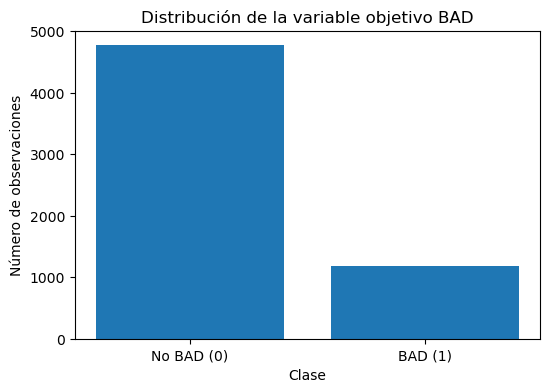

In [33]:
bad_counts = df["BAD"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["No BAD (0)", "BAD (1)"], bad_counts.values)

plt.title("Distribución de la variable objetivo BAD")
plt.ylabel("Número de observaciones")
plt.xlabel("Clase")

plt.show()

In [ ]:
#### Interpretación

La variable objetivo presenta una distribución desigual entre sus dos clases.
El 80,05 % de las observaciones corresponde a `BAD = 0`, mientras que el
19,95 % corresponde a `BAD = 1`.

Por tanto, existe cierto desbalance de clases, aunque no es extremo. Esta
característica deberá tenerse en cuenta posteriormente durante la construcción
y evaluación de los modelos predictivos, ya que métricas como la exactitud
(*accuracy*) podrían ofrecer una visión incompleta del rendimiento del modelo.

In [ ]:
## 10. Conclusiones del análisis inicial

El conjunto de datos HMEQ contiene 5.960 observaciones y 13 variables relacionadas
con las características financieras, crediticias y laborales de los solicitantes.

Durante esta primera fase de comprensión y evaluación de la calidad de los datos
se han obtenido las siguientes conclusiones:

- No se han identificado observaciones completamente duplicadas.
- Las variables categóricas `REASON` y `JOB` presentan categorías consistentes,
  aunque contienen algunos valores ausentes.
- Existen valores ausentes en varias variables. `DEBTINC` presenta la mayor
  proporción de ausencia, con aproximadamente un 21,26 %.
- El 43,56 % de las observaciones contiene al menos un valor ausente.
- La presencia de valores ausentes no parece comportarse de manera homogénea
  entre las diferentes variables.
- Se ha observado una asociación descriptiva especialmente relevante entre la
  ausencia de `DEBTINC` y `BAD`: la tasa de `BAD` es del 62,04 % cuando
  `DEBTINC` está ausente, frente al 8,59 % cuando está disponible.
- También se han identificado patrones conjuntos de ausencia entre determinadas
  variables crediticias, especialmente `CLAGE`, `CLNO`, `DELINQ`, `NINQ` y
  `DEROG`.
- No se han detectado inicialmente valores negativos o rangos evidentemente
  imposibles, aunque algunas variables presentan valores extremos que deberán
  estudiarse durante el análisis exploratorio.
- La variable objetivo `BAD` presenta una distribución del 80,05 % para la clase
  0 y del 19,95 % para la clase 1, por lo que existe cierto desbalance entre
  las clases.

### Decisiones para las siguientes fases

En esta etapa no se eliminarán observaciones ni se imputarán valores ausentes,
ya que se ha observado que la ausencia de información puede contener señal
relevante respecto al riesgo de crédito.

El siguiente paso será realizar un análisis exploratorio de datos (EDA),
estudiando las distribuciones de las variables, su tendencia central,
dispersión, asimetría, posibles valores atípicos y su relación con la variable
objetivo `BAD`.

In [ ]:
01_data_understanding.ipynb

Problema
   ↓
Carga de datos
   ↓
Estructura del dataset
   ↓
Tipos de variables
   ↓
Estadística descriptiva inicial
   ↓
Data Quality
   ↓
Missing values
   ↓
Target
   ↓
CONCLUSIONES
   ↓
Decisiones para la siguiente fase